# AAM: windowed STFT chord recognition
Audio → frequency filter → bass/middle chroma → Gaussian scores → HMM → play-along CSV.

The same 600/200/200 song split, 25 chord/rest labels and exact-time metrics are used for every window setup. Validation chooses the feature setup and smoothing weight; the test set evaluates that fixed choice. N.C. counts as a regular label, with no separate tuning or report.

Keep `project_path` unchanged to reuse existing prepared audio. Filtering changes the features, so this version uses a new feature/model cache. Nothing is downloaded from Zenodo.

## 1. Setup and experiment settings
The default grid compares four STFT setups: 200 or 400 ms Hann windows, each with 25% or 75% overlap. Validation also chooses the HMM smoothing weight.

A 20 Hz high-pass removes very low-frequency content. A 20 kHz low-pass is used only when the sample rate supports it. At 22,050 Hz sampling, resampling already removes frequencies above the 11,025 Hz Nyquist limit. This filter does not remove noise within the musical frequency range.

In [1]:
%pip -q install librosa==0.11.0 soundfile pandas matplotlib scipy scikit-learn tqdm
from pathlib import Path
import json
import hashlib
import re
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from scipy.signal import butter, sosfiltfilt
from scipy.stats import multivariate_normal
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import train_test_split
from IPython.display import display
from tqdm.auto import tqdm
from google.colab import drive

drive.mount("/content/drive")
project_path = Path("/content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data")
audio_folder = project_path / "0001-1000-audio-mixes"
ground_truth_path = project_path / "aam_cleaned_csv"
results_path = project_path / "aam_window_hmm_results"
local_path = Path("/content/aam")
for folder in [results_path, local_path]:
    folder.mkdir(parents=True, exist_ok=True)

sample_rate = 22050
seed = 42
low_cut_hz, high_cut_hz = 20.0, 20000.0
filter_order = 4
onset_tolerance_s = 0.1
window_sizes_ms = [200, 400]
overlaps = [0.25, 0.75]
# To restore the full STFT grid: use range(100, 501, 100) and [0, .25, .5, .75].
weights = [0.0, 1.0, 2.0, 3.0, 4.0, 6.0]
configs = [{"method": "stft", "window_ms": ms, "overlap": overlap}
           for ms in window_sizes_ms for overlap in overlaps]
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
chords = np.array([note + quality for note in notes for quality in ["maj", "min"]])
states = np.append(chords, "N")
state_to_id = {label: i for i, label in enumerate(states)}
print(f"{len(configs)} feature setups × {len(weights)} weights = {len(configs)*len(weights)} validation settings")


Mounted at /content/drive
4 feature setups × 6 weights = 24 validation settings


## 2. Read cleaned annotations and keep the same split
Use original-pitch chords from the preprocessing CSVs. Training rotates chord patterns to a shared root internally; prediction does not need the song's true key. Unknown annotation gaps are not treated as N.C.

In [2]:
def normalize_chord(label):
    label = label.strip().strip("'\"")
    if label.lower() in ["n", "n.c.", "nc", "none", "x", "?"]:
        return "N"
    match = re.fullmatch(r"([A-G])([#b]?)(?::|_)?(maj|min|m|M)?", label)
    if match is None:
        raise ValueError(f"Unsupported chord: {label}")
    letter, accidental, quality = match.groups()
    root = {"C": 0, "D": 2, "E": 4, "F": 5, "G": 7, "A": 9, "B": 11}[letter]
    root += {None: 0, "": 0, "#": 1, "b": -1}[accidental]
    quality = "min" if quality in ["min", "m"] else "maj"
    return notes[root % 12] + quality


def read_ground_truth(file_path):
    table = pd.read_csv(file_path)
    required = {"time_s", "end_time_s", "bar", "quarter", "chord"}
    assert required.issubset(table.columns), f"Missing CSV columns: {file_path.name}"
    if "original_chord" in table:
        table["chord"] = table.original_chord
    elif "transpose_semitones" in table and "chord_C" not in table:
        assert table.transpose_semitones.eq(0).all(), "Use original-pitch chords, not C-normalized targets."
    table = table.rename(columns={"time_s": "start", "end_time_s": "end"})
    table = table[["start", "end", "bar", "quarter", "chord"]].copy()
    for column in ["start", "end", "bar", "quarter"]:
        table[column] = pd.to_numeric(table[column])
    assert table.chord.notna().all(), f"Missing chord labels: {file_path.name}"
    table["chord"] = table.chord.map(normalize_chord)

    assert len(table) > 1, f"Too few rows: {file_path.name}"
    assert np.isfinite(table[["start", "end", "bar", "quarter"]]).all().all()
    assert (np.diff(table.start) > 0).all(), f"Duplicate/backward times: clean {file_path.name} first."
    assert table.start.iloc[0] >= 0 and (table.end > table.start).all()
    assert (table.end.iloc[:-1].to_numpy() <= table.start.iloc[1:].to_numpy() + 1e-7).all()
    assert np.allclose(table[["bar", "quarter"]], np.round(table[["bar", "quarter"]]))
    assert table.bar.ge(1).all() and table.quarter.isin([1, 2, 3, 4]).all()
    return table


def labels_at(times, table):
    labels = np.full(len(times), "UNANNOTATED", dtype="<U16")
    if len(table) == 0:
        return labels
    indices = np.searchsorted(table.start.to_numpy(), times, side="right") - 1
    safe = np.clip(indices, 0, len(table) - 1)
    valid = (indices >= 0) & (times < table.end.to_numpy()[safe])
    labels[valid] = table.chord.to_numpy()[safe[valid]]
    return labels

song_ids = [f"{i:04d}" for i in range(1, 1001)]
annotation_files = {}
for path in ground_truth_path.rglob("*_ground_truth.csv"):
    song_id = path.name.split("_")[0]
    assert song_id not in annotation_files, f"Duplicate annotations: {song_id}"
    annotation_files[song_id] = path
assert set(annotation_files) == set(song_ids), "Expected cleaned annotations for songs 0001–1000."
ground_truth = {song_id: read_ground_truth(annotation_files[song_id]) for song_id in song_ids}
train_ids, remaining = train_test_split(song_ids, test_size=0.4, random_state=seed)
val_ids, test_ids = train_test_split(remaining, test_size=0.5, random_state=seed)
split = {"train": sorted(train_ids), "validation": sorted(val_ids), "test": sorted(test_ids)}
annotation_text = "".join(song_id + ground_truth[song_id].to_csv(index=False) for song_id in song_ids)
experiment = {"version": 3, "sr": sample_rate, "filter": [low_cut_hz, high_cut_hz, filter_order],
              "features": "bass_mid_chroma_energy_flatness_26_stft",
              "tuning": 0,
              "annotations": hashlib.sha256(annotation_text.encode()).hexdigest(), "split": split}
run_id = hashlib.sha256(json.dumps(experiment, sort_keys=True).encode()).hexdigest()[:16]
cache_path = results_path / "cache" / run_id
local_cache = local_path / "cache" / run_id
for folder in [cache_path, local_cache]:
    folder.mkdir(parents=True, exist_ok=True)
print({name: len(ids) for name, ids in split.items()})


{'train': 600, 'validation': 200, 'test': 200}


## 3. Read audio once and cache the filtered signal
Original mixes are copied to local disk before decoding. Already prepared mono audio from earlier notebooks is reused when present. The filtered signal is cached separately, so reruns need neither a download nor repeated filtering.

If Drive disconnects, remount it with `drive.mount("/content/drive", force_remount=True)` and rerun the failed cell. Keep the runtime to preserve local files.

In [3]:
audio_files = {}
for path in audio_folder.rglob("*"):
    match = re.fullmatch(r"(\d{4})_mix\.(flac|wav|mp3)", path.name, re.IGNORECASE)
    if match and path.is_file():
        assert match.group(1) not in audio_files, f"Duplicate audio: {path.name}"
        audio_files[match.group(1)] = path

# Two small helpers keep cache writes atomic and local reads fast.
def local_copy(source, target):
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(target.suffix + ".part")
    shutil.copyfile(source, temporary)
    assert temporary.stat().st_size == source.stat().st_size, f"Incomplete copy: {source.name}"
    temporary.replace(target)
    return target


def save_arrays(relative, **arrays):
    local_file = local_cache / relative
    local_file.parent.mkdir(parents=True, exist_ok=True)
    temporary = local_file.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, **arrays)
    temporary.replace(local_file)
    local_copy(local_file, cache_path / relative)


def cached_file(relative):
    local_file = local_cache / relative
    if local_file.exists():
        return local_file
    drive_file = cache_path / relative
    return local_copy(drive_file, local_file) if drive_file.exists() else None


def filter_audio(audio, sr):
    if high_cut_hz < sr / 2:
        sos = butter(filter_order, [low_cut_hz, high_cut_hz], btype="bandpass", fs=sr, output="sos")
    else:
        sos = butter(filter_order, low_cut_hz, btype="highpass", fs=sr, output="sos")
    # Forward/backward filtering avoids a systematic phase delay (offline processing).
    return sosfiltfilt(sos, audio).astype(np.float32)


filter_id = hashlib.sha256(json.dumps([sample_rate, low_cut_hz, high_cut_hz, filter_order]).encode()).hexdigest()[:10]
prepared_folder = results_path / "prepared_audio" / f"filtered_{filter_id}_v1"
local_prepared = local_path / "prepared_audio" / prepared_folder.name
old_prepared = results_path / "prepared_audio" / f"mono_sr{sample_rate}_librosa011_v1"
old_local_prepared = local_path / "prepared_audio" / old_prepared.name
for folder in [prepared_folder, local_prepared]:
    folder.mkdir(parents=True, exist_ok=True)


def load_audio(song_id):
    local_file = local_prepared / f"{song_id}.npy"
    saved_file = prepared_folder / local_file.name
    if not local_file.exists():
        if saved_file.exists():
            local_copy(saved_file, local_file)
        else:
            raw_file = old_local_prepared / local_file.name
            if not raw_file.exists() and (old_prepared / local_file.name).exists():
                local_copy(old_prepared / local_file.name, raw_file)
            if raw_file.exists():
                audio = np.load(raw_file, allow_pickle=False)
            else:
                assert song_id in audio_files, f"Missing audio for {song_id}; check audio_folder."
                source = audio_files[song_id]
                mix_file = local_path / "audio_mixes" / source.name
                if not mix_file.exists():
                    local_copy(source, mix_file)
                audio, _ = librosa.load(mix_file, sr=sample_rate, mono=True)
            temporary = local_file.with_suffix(".tmp.npy")
            np.save(temporary, filter_audio(audio, sample_rate), allow_pickle=False)
            temporary.replace(local_file)
            local_copy(local_file, saved_file)
    return np.load(local_file, mmap_mode="r", allow_pickle=False)


## 4. Windowed STFT features
Each Hann window produces **26 features**: 12 bass chroma values (C1–C4), 12 middle-register values (C4–C6), log energy and spectral flatness.

Window size controls how much audio contributes to each chroma vector. Overlap controls how frequently windows are sampled. Energy and flatness use a fixed 2,048-sample STFT, interpolated at the chroma frame centers.

Feature timestamps are centered. Predicted interval boundaries lie halfway between neighboring frame centers.

STFT edge windows explicitly use zero padding (`center=True`, `pad_mode="constant"`), matching the original defaults. Padding is analysis context, not extra song time. Only frame centers inside the audio are retained; the final interval ends at `len(audio) / sample_rate`. Cached features are checked against that duration too.


In [4]:
def config_key(config):
    return f"stft_w{config['window_ms']}_o{round(100*config['overlap'])}"


def frame_edges(centers, duration):
    assert duration > 0 and len(centers), "Audio must contain at least one frame."
    assert np.isfinite(centers).all() and ((centers >= 0) & (centers < duration)).all()
    assert (np.diff(centers) > 0).all(), "Frame centers must increase."
    return np.r_[0, (centers[:-1] + centers[1:]) / 2, duration]


def normalize_chroma(chroma):
    return chroma / np.maximum(np.linalg.norm(chroma, axis=0, keepdims=True), 1e-10)


def extra_features(audio):
    power = np.abs(librosa.stft(audio, n_fft=2048, hop_length=512, window="hann",
                                    center=True, pad_mode="constant")) ** 2
    times = np.arange(power.shape[1]) * 512 / sample_rate
    energy = np.log10(np.maximum(power.mean(axis=0) / 2048**2, 1e-12))
    flatness = librosa.feature.spectral_flatness(S=power, power=1.0)[0]
    return times, energy, flatness


def extract_features(audio, config, extras=None):
    if extras is None:
        extras = extra_features(audio)
    duration = len(audio) / sample_rate
    win = round(sample_rate * config["window_ms"] / 1000)
    hop = max(1, round(win * (1-config["overlap"])))
    n_fft = 2 ** int(np.ceil(np.log2(win)))
    power = np.abs(librosa.stft(audio, n_fft=n_fft, win_length=win,
                               hop_length=hop, window="hann", center=True, pad_mode="constant")) ** 2
    frequencies = librosa.fft_frequencies(sr=sample_rate, n_fft=n_fft)
    chroma_filter = librosa.filters.chroma(sr=sample_rate, n_fft=n_fft, tuning=0, octwidth=None)
    bass_mask = (frequencies >= librosa.note_to_hz("C1")) & (frequencies < librosa.note_to_hz("C4"))
    mid_mask = (frequencies >= librosa.note_to_hz("C4")) & (frequencies < librosa.note_to_hz("C6"))
    bass = normalize_chroma(chroma_filter[:, bass_mask] @ power[bass_mask])
    middle = normalize_chroma(chroma_filter[:, mid_mask] @ power[mid_mask])
    centers = np.arange(bass.shape[1]) * hop / sample_rate
    keep = centers < duration
    centers = centers[keep]
    extra_times, energy, flatness = extras
    features = np.column_stack([bass[:, keep].T, middle[:, keep].T,
        np.interp(centers, extra_times, energy), np.interp(centers, extra_times, flatness)]).astype(np.float32)
    assert len(features) and np.isfinite(features).all()
    return features, centers, frame_edges(centers, duration)


**Feature cache: reuse extracted arrays**

In [5]:
def get_features(song_id, config, audio=None, extras=None):
    relative = Path(config_key(config)) / f"{song_id}_features.npz"
    if audio is None:
        audio = load_audio(song_id)
    duration = len(audio) / sample_rate
    path = cached_file(relative)
    if path is not None:
        with np.load(path, allow_pickle=False) as saved:
            features, centers = saved["features"], saved["centers"]
        # Cached frames must also obey the actual audio duration.
        keep = (centers >= 0) & (centers < duration)
        features, centers = features[keep], centers[keep]
        return features, centers, frame_edges(centers, duration)
    features, centers, edges = extract_features(audio, config, extras)
    save_arrays(relative, features=features, centers=centers, edges=edges)
    return features, centers, edges


def prepare_features(song_ids, settings, description):
    for song_id in tqdm(song_ids, desc=description, unit="song"):
        missing = [config for config in settings
                   if cached_file(Path(config_key(config))/f"{song_id}_features.npz") is None]
        if missing:
            audio = load_audio(song_id)
            extras = extra_features(audio)
            for config in missing:
                get_features(song_id, config, audio, extras)


## 5. Fit the chord models and decode a sequence
Training rotates major/minor patterns to a common root and fits one Gaussian for each quality, plus the rest label. Root rotation produces scores for all 24 major/minor chords. The HMM learns transitions from training annotations and uses Viterbi decoding to combine chord evidence with sequence continuity.

A weight of zero classifies windows independently. Larger weights give transitions more influence. Features and models are cached separately for every setup.

In [6]:
def align_root(features, root):
    aligned = features.copy()
    aligned[:, :24] = np.roll(features[:, :24].reshape(-1, 2, 12), -root, axis=2).reshape(-1, 24)
    return aligned


def train_model(config):
    relative = Path(config_key(config)) / "model.npz"
    path = cached_file(relative)
    if path is not None:
        with np.load(path, allow_pickle=False) as saved:
            return dict(saved)
    rng = np.random.default_rng(seed)
    groups = [[], [], []]
    transitions = np.full((25, 25), 0.5)
    initial = np.full(25, 0.5)
    for song_id in tqdm(split["train"], desc=f"Fit {config_key(config)}", unit="song", leave=False):
        features, centers, edges = get_features(song_id, config)
        truth = ground_truth[song_id]
        assert truth.end.iloc[-1] <= edges[-1]+0.1, f"Annotations exceed audio: {song_id}"
        ids = np.array([state_to_id.get(label, -1) for label in labels_at(centers, truth)])
        valid = (ids[:-1] >= 0) & (ids[1:] >= 0)
        for start, end in zip(truth.end.iloc[:-1], truth.start.iloc[1:]):
            if end > start+1e-7:
                valid &= ~((centers[:-1] < end) & (centers[1:] >= start))
        np.add.at(transitions, (ids[:-1][valid], ids[1:][valid]), 1)
        if ids[0] >= 0:
            initial[ids[0]] += 1
        for group in range(3):
            mask = ids == 24 if group == 2 else ((ids >= 0) & (ids < 24) & (ids % 2 == group))
            selected = np.flatnonzero(mask)
            if len(selected) > 300:
                selected = rng.choice(selected, 300, replace=False)
            if not len(selected):
                continue
            sample = features[selected].copy()
            if group < 2:
                for root in range(12):
                    mask = ids[selected] // 2 == root
                    sample[mask] = align_root(sample[mask], root)
            groups[group].append(sample)
    means, covariances = [], []
    for group in groups:
        assert group, "A training label group has no examples."
        fitted = LedoitWolf().fit(np.vstack(group))
        means.append(fitted.location_)
        covariances.append(fitted.covariance_ + 1e-4*np.eye(26))
    model = {"means": np.array(means), "covariances": np.array(covariances),
             "transitions": transitions/transitions.sum(axis=1, keepdims=True),
             "initial": initial/initial.sum()}
    save_arrays(relative, **model)
    return model


**Score chords and decode the HMM**

In [7]:
def emission_scores(features, model):
    scores = np.empty((len(features), 25))
    for root in range(12):
        aligned = align_root(features, root)
        for quality in range(2):
            scores[:, 2 * root + quality] = multivariate_normal.logpdf(
                aligned, mean=model["means"][quality], cov=model["covariances"][quality])
    scores[:, 24] = multivariate_normal.logpdf(features, mean=model["means"][2], cov=model["covariances"][2])
    return scores


def decode(scores, model, weight):
    if not len(scores):
        return np.array([], dtype=int)
    if weight == 0:
        return scores.argmax(axis=1)
    back = np.zeros(scores.shape, dtype=np.int16)
    best = scores[0] + np.log(model["initial"])
    transitions = weight * np.log(model["transitions"])
    for t in range(1, len(scores)):
        candidates = best[:, None] + transitions
        back[t] = candidates.argmax(axis=0)
        best = scores[t] + candidates[back[t], np.arange(25)]
    path = np.empty(len(scores), dtype=int)
    path[-1] = best.argmax()
    for t in range(len(scores) - 2, -1, -1):
        path[t] = back[t + 1, path[t + 1]]
    return path


def interval_table(edges, ids):
    return pd.DataFrame({"start": edges[:-1], "end": edges[1:], "chord": states[ids]})


def merge_intervals(table):
    groups = table.chord.ne(table.chord.shift()).cumsum()
    return table.groupby(groups, sort=False).agg(start=("start", "first"),
                                                end=("end", "last"), chord=("chord", "first")).reset_index(drop=True)


def valid_prediction_bounds(prediction, duration):
    """Require full coverage of the audio and no intervals outside it."""
    if prediction.empty:
        return False
    start, end = prediction.start.to_numpy(), prediction.end.to_numpy()
    return bool(
        np.isfinite(start).all() and np.isfinite(end).all()
        and (start >= 0).all() and (end <= duration).all() and (end > start).all()
        and np.isclose(start[0], 0, atol=1e-7, rtol=0)
        and np.isclose(end[-1], duration, atol=1e-7, rtol=0)
        and np.allclose(end[:-1], start[1:], atol=1e-7, rtol=0)
    )


def clean_test_ending(prediction, annotation_end):
    """Trim the evaluation outro and carry the last chord through a final N interval."""
    prediction = prediction[prediction.start < annotation_end].copy()
    prediction["end"] = prediction.end.clip(upper=annotation_end)
    prediction = prediction[prediction.end > prediction.start].reset_index(drop=True)
    if len(prediction) > 1 and prediction.chord.iloc[-1] == "N":
        prediction = prediction.iloc[:-1].copy()
        prediction.loc[prediction.index[-1], "end"] = annotation_end
    return prediction


## 6. Accuracy, change timing and CSV helpers
**Overall accuracy** is correct chord/rest-label seconds divided by all annotated seconds. **Chord accuracy** uses chord-labeled time only. Unknown gaps are excluded.

Change precision, recall and F1 use one-to-one matches within ±100 ms. Timing matches do not require the correct destination chord. Matched MAE describes matched events only, so read it with F1. This model estimates chord-change times, not beats or bars.

Exported CSVs retain the annotation column names. `bar` and `quarter` are blank until an audio-based beat/downbeat tracker is added. `next_chord` and `next_time_s` support play-along displays.

In [8]:
def play_along_csv(prediction):
    """One row per predicted interval, using the annotation column names."""
    output = prediction[["start", "end", "chord"]].rename(
        columns={"start": "time_s", "end": "end_time_s"}).copy()
    # Beat/bar positions are unavailable in this window-only model.
    output["bar"] = pd.array([pd.NA] * len(output), dtype="Int64")
    output["quarter"] = pd.array([pd.NA] * len(output), dtype="Int64")
    output["next_chord"] = output.chord.shift(-1).fillna("")
    output["next_time_s"] = output.time_s.shift(-1)
    return output[["time_s", "bar", "quarter", "chord", "end_time_s", "next_chord", "next_time_s"]]


def load_interval_csv(path):
    """Read both the new play-along schema and older saved predictions."""
    table = pd.read_csv(path).rename(columns={"time_s": "start", "start_time_s": "start",
                                             "end_time_s": "end"})
    return table[["start", "end", "chord"]]


**Score correct seconds and chord-change timing**

In [9]:
def time_metrics(truth, prediction, duration):
    boundaries = np.unique(np.clip(np.r_[0, duration, truth.start, truth.end,
                                         prediction.start, prediction.end], 0, duration))
    lengths = np.diff(boundaries)
    mids = (boundaries[:-1] + boundaries[1:]) / 2
    true = labels_at(mids, truth)
    predicted = labels_at(mids, prediction)
    known = np.isin(true, states)
    chord = np.isin(true, chords)
    correct = known & (true == predicted)
    return {"duration_s": duration, "annotated_s": lengths[known].sum(),
            "correct_s": lengths[correct].sum(), "chord_s": lengths[chord].sum(),
            "correct_chord_s": lengths[correct & chord].sum()}


def summarize_metrics(table):
    total = table.sum(numeric_only=True)
    def ratio(a, b):
        return float(total[a] / total[b]) if total[b] else np.nan
    return {"all_label_time_accuracy": ratio("correct_s", "annotated_s"),
            "chord_only_time_accuracy": ratio("correct_chord_s", "chord_s")}


def chord_onsets(table, reference, duration, is_reference=False):
    if len(table) < 2:
        return pd.DataFrame(columns=["time", "chord"])
    starts = table.start.to_numpy()[1:]
    current = table.chord.to_numpy()[1:]
    previous = table.chord.to_numpy()[:-1]
    keep = np.isin(current, states) & np.isin(previous, states) & (current != previous) & (starts > 0) & (starts < duration)
    if is_reference:
        keep &= np.isclose(table.end.to_numpy()[:-1], starts, atol=1e-7, rtol=0)
    else:
        # Both sides must be annotated, so unknown gaps cannot create scored events.
        keep &= np.isin(labels_at(starts, reference), states)
        keep &= np.isin(labels_at(starts - 1e-7, reference), states)
    return pd.DataFrame({"time": starts[keep], "chord": current[keep]})


def match_chord_onsets(truth, prediction, duration, tolerance):
    true_times = chord_onsets(truth, truth, duration, is_reference=True).time.to_numpy()
    predicted_times = chord_onsets(prediction, truth, duration).time.to_numpy()
    i, j = 0, 0
    errors = []
    # Match each change at most once, in time order.
    while i < len(true_times) and j < len(predicted_times):
        difference = predicted_times[j] - true_times[i]
        if abs(difference) <= tolerance:
            errors.append(abs(difference))
            i += 1
            j += 1
        elif difference < 0:
            j += 1
        else:
            i += 1
    matched, true, predicted = len(errors), len(true_times), len(predicted_times)
    return {
        "onset_true_count": true, "onset_predicted_count": predicted,
        "onset_matched_count": matched, "onset_absolute_error_sum_s": float(sum(errors)),
        "onset_precision": matched / predicted if predicted else np.nan,
        "onset_recall": matched / true if true else np.nan,
        "onset_f1": 2 * matched / (true + predicted) if true + predicted else np.nan,
        "matched_onset_mae_s": float(np.mean(errors)) if errors else np.nan,
        "onset_tolerance_s": tolerance
    }


def summarize_timing(table):
    total = table.sum(numeric_only=True)
    matched = total.onset_matched_count
    true, predicted = total.onset_true_count, total.onset_predicted_count
    return {
        "change_precision": matched / predicted if predicted else np.nan,
        "change_recall": matched / true if true else np.nan,
        "change_f1": 2 * matched / (true + predicted) if true + predicted else np.nan,
        "matched_change_mae_ms": 1000 * total.onset_absolute_error_sum_s / matched if matched else np.nan
    }


## 7. Prepare training features and fit/load models
The preparation loop visits each song once and creates only missing features. Local files are used for fitting; completed files are saved to Drive. The simpler STFT path uses standard librosa calls instead of the earlier custom shared-FFT code.

In [10]:
missing_models = [config for config in configs if cached_file(Path(config_key(config))/"model.npz") is None]
if missing_models:
    prepare_features(split["train"], missing_models, "Prepare training features")
models = {config_key(config): train_model(config) for config in tqdm(configs, desc="Train/load models")}


Train/load models:   0%|          | 0/4 [00:00<?, ?it/s]

## 8. Compare window settings on validation
For each setup, compute Gaussian scores once per song and reuse them across smoothing weights. Each completed song's metrics are saved, so interrupted validation resumes. A single search replaces the earlier coarse/refinement/calibration machinery.


In [11]:
search = {"configs": configs, "weights": weights, "tolerance": onset_tolerance_s}
search_id = hashlib.sha256(json.dumps(search, sort_keys=True).encode()).hexdigest()[:12]
validation_rows = []
for config in tqdm(configs, desc="Validate feature setups"):
    key = config_key(config)
    model = models[key]
    relative = Path(key) / f"validation_{search_id}.json"
    progress_file = cached_file(relative)
    progress = json.loads(progress_file.read_text()) if progress_file else {}
    for song_id in tqdm(split["validation"], desc=key, unit="song", leave=False):
        if song_id in progress:
            continue
        features, centers, edges = get_features(song_id, config)
        scores = emission_scores(features, model)
        results = []
        for weight in weights:
            prediction = merge_intervals(interval_table(edges, decode(scores, model, weight)))
            timing = match_chord_onsets(ground_truth[song_id], prediction, edges[-1], onset_tolerance_s)
            results.append({**time_metrics(ground_truth[song_id], prediction, edges[-1]), **timing})
        progress[song_id] = results
        local_file = local_cache / relative
        temporary = local_file.with_suffix(".tmp.json")
        temporary.write_text(json.dumps(progress))
        temporary.replace(local_file)
        local_copy(local_file, cache_path / relative)
    for j, weight in enumerate(weights):
        table = pd.DataFrame([progress[song_id][j] for song_id in split["validation"]])
        timing = summarize_timing(table)
        validation_rows.append({"setup": key, "method": config["method"], "weight": weight,
            **summarize_metrics(table),
            "change_f1": timing["change_f1"],
            "matched_change_mae_ms": timing["matched_change_mae_ms"]})
validation_results = pd.DataFrame(validation_rows).sort_values(
    ["all_label_time_accuracy", "change_f1", "weight"], ascending=[False, False, True]).reset_index(drop=True)
validation_results.to_csv(cache_path / f"validation_{search_id}.csv", index=False)
result_columns = ["setup", "weight", "all_label_time_accuracy", "chord_only_time_accuracy", "change_f1", "matched_change_mae_ms"]
print("Best settings (accuracy and F1 are fractions; MAE is milliseconds):")
display(validation_results[result_columns].head(10).round(4))


Validate feature setups:   0%|          | 0/4 [00:00<?, ?it/s]

stft_w200_o25:   0%|          | 0/200 [00:00<?, ?song/s]

stft_w200_o75:   0%|          | 0/200 [00:00<?, ?song/s]

stft_w400_o25:   0%|          | 0/200 [00:00<?, ?song/s]

stft_w400_o75:   0%|          | 0/200 [00:00<?, ?song/s]

Best settings (accuracy and F1 are fractions; MAE is milliseconds):


,setup,weight,all_label_time_accuracy,chord_only_time_accuracy,change_f1,matched_change_mae_ms
0,stft_w200_o25,6.0,0.8546,0.8606,0.7488,41.2818
1,stft_w200_o25,4.0,0.8415,0.8502,0.7143,41.2500
2,stft_w400_o75,6.0,0.8352,0.8431,0.6675,41.5682
3,stft_w400_o25,6.0,0.8315,0.8359,0.4959,48.0558
4,stft_w200_o25,3.0,0.8296,0.8395,0.6821,41.3022
5,stft_w400_o25,4.0,0.8292,0.8350,0.4883,47.8769
6,stft_w200_o75,6.0,0.8288,0.8393,0.6967,27.8222
7,stft_w400_o75,4.0,0.8235,0.8332,0.6336,41.5000
8,stft_w400_o25,3.0,0.8227,0.8299,0.4793,47.9764
9,stft_w400_o75,3.0,0.8147,0.8258,0.6058,41.4813


### Findings from the supplied run (recorded before this cleanup)

| Validation winner | Overall time accuracy | Chord-only accuracy | Change F1 | Matched change MAE |
| --- | ---: | ---: | ---: | ---: |
| STFT: 200 ms, 25% overlap, weight 6 | 85.46% | 86.06% | 74.88% | 41.28 ms |

The best tested setup uses a 200 ms Hann window, 25% overlap and HMM weight 6. Its frame spacing is about 150 ms; this is not the matched timing error. Higher overlap did not win the tested grid.

Weight 6 is the largest tested weight, so stronger smoothing could be tested on validation in a future experiment. This run does not establish that 6 is globally optimal.

The selected STFT model's **200-song test** result is **85.80% overall time accuracy**, **86.77% chord-only accuracy**, **72.98% change precision**, **83.21% change recall**, **77.76% change F1**, and **41.12 ms matched-change MAE**. Of 13,941 reference changes, 11,600 were matched; 15,894 changes were predicted. Thus 2,341 reference changes were missed and 4,294 predictions were unmatched at ±100 ms. Timing matches do not require the correct chord. MAE excludes unmatched events. These are chord-change metrics, not beat-timing metrics.

The typical song is better than the overall average: median 90.32%, middle half 80.20–95.41%, minimum 30.12%. A small number of difficult songs pull the average down. For example, 0894 has 30.12% overall but 97.23% chord-only accuracy, pointing to errors in annotated non-chord time rather than poor recognition throughout that song. This remains part of overall accuracy, not a separate optimization target.

These figures came from the uploaded notebook's saved outputs. Cleanup preserves the feature/model definitions, selection rules and splits; it has not rerun the full experiment. The cells below will show current results when run in Colab.

The recorded scores above precede terminal-N cleanup. Step 10 now scores postprocessed test predictions, so rerun it and step 11 for updated values.


## 9. Save the winning model
Select by overall exact-time validation accuracy, then change F1 on exact ties. No test song participates in selection.

In [12]:
chosen = validation_results.iloc[0]
chosen_config = next(config for config in configs if config_key(config) == chosen.setup)
chosen_weight = float(chosen.weight)
chosen_model = models[chosen.setup]
selection = {"config": chosen_config, "weight": chosen_weight, "experiment": experiment,
             "states": states.tolist(), "selection_metric": "all_label_time_accuracy"}
selection_hash = hashlib.sha256(json.dumps(selection, sort_keys=True).encode()).hexdigest()[:16]
model_path = results_path / f"window_hmm_{selection_hash}.npz"
if not model_path.exists():
    temporary = model_path.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, **chosen_model, selection=np.array(json.dumps(selection)))
    temporary.replace(model_path)
print("Selected:", chosen.setup, "weight:", chosen_weight)
print("Saved model:", model_path)


Selected: stft_w200_o25 weight: 6.0
Saved model: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/window_hmm_4f12560a1fd5a9f6.npz


## 10. Test and export clean CSVs
The existing test CSVs and metrics are rewritten. Predictions are cut at the final annotated **end_time_s**. If the last remaining interval is N and an earlier chord exists, remove that interval and extend the previous predicted chord to the cutoff. N intervals elsewhere remain unchanged; an all-N prediction is retained because there is no chord to carry forward.

Accuracy and change metrics are recalculated **after this ending cleanup**. Carrying the last chord forward is a postprocessing rule, not a newly learned prediction; it can help or hurt the score. Only the cutoff comes from annotations, never the final true chord. These scores use known evaluation boundaries. Validation selection still uses the original predictions. New-audio inference in step 14 retains audio-duration bounds.

CSV columns: `time_s, bar, quarter, chord, end_time_s, next_chord, next_time_s`. Beat/bar positions remain blank. The last row has no next instruction.


In [13]:
evaluation_path = results_path / "evaluation" / selection_hash
local_evaluation = local_path / "evaluation" / selection_hash
for folder in [evaluation_path, local_evaluation]:
    folder.mkdir(parents=True, exist_ok=True)
metric_rows = []
boundary_rows = []
for song_id in tqdm(split["test"], desc="Predict/test/export", unit="song"):
    audio = load_audio(song_id)
    duration = len(audio) / sample_rate  # Real samples only; never padded STFT length.
    truth = ground_truth[song_id]
    metric_path = evaluation_path / f"{song_id}_metrics.json"
    prediction_path = evaluation_path / f"{song_id}_predictions.csv"
    prediction = load_interval_csv(prediction_path) if prediction_path.exists() else pd.DataFrame()
    annotation_end = min(duration, float(truth.end.max()))
    reused = (valid_prediction_bounds(prediction, duration)
              or valid_prediction_bounds(prediction, annotation_end))
    if not reused:
        # Redecode invalid cached exports with the existing fitted model.
        features, centers, edges = get_features(song_id, chosen_config, audio=audio)
        ids = decode(emission_scores(features, chosen_model), chosen_model, chosen_weight)
        prediction = merge_intervals(interval_table(edges, ids))
    prediction = clean_test_ending(prediction, annotation_end)
    assert valid_prediction_bounds(prediction, annotation_end), f"Invalid annotation bounds: {song_id}"
    timing = match_chord_onsets(truth, prediction, annotation_end, onset_tolerance_s)
    row = {"song_id": song_id, **time_metrics(truth, prediction, annotation_end), **timing,
           "ending_policy": "annotation_cutoff_and_terminal_N_carry_forward"}
    # Refresh CSV instructions and metrics even when predictions were reused.
    local_prediction = local_evaluation / prediction_path.name
    play_along_csv(prediction).to_csv(local_prediction, index=False)
    local_copy(local_prediction, prediction_path)
    local_metric = local_evaluation / metric_path.name
    local_metric.write_text(json.dumps(row))
    local_copy(local_metric, metric_path)
    metric_rows.append(row)
    boundary_rows.append({
        "song_id": song_id, "audio_duration_s": duration,
        "last_beat_start_s": truth.start.iloc[-1], "annotation_end_s": truth.end.max(),
        "prediction_end_s": prediction.end.max(),
        "unannotated_tail_s": max(0.0, duration - truth.end.max()),
        "reused_predictions": reused
    })
boundary_report = pd.DataFrame(boundary_rows)
boundary_report.to_csv(evaluation_path / "test_audio_boundaries.csv", index=False)
print("Updated prediction CSVs and metrics:", evaluation_path)
metrics = pd.DataFrame(metric_rows)
metrics["all_label_accuracy"] = metrics.correct_s / metrics.annotated_s.replace(0, np.nan)
metrics["chord_only_accuracy"] = metrics.correct_chord_s / metrics.chord_s.replace(0, np.nan)
metric_columns = ["song_id", "all_label_accuracy", "chord_only_accuracy", "onset_precision", "onset_recall",
                  "onset_f1", "matched_onset_mae_s"]
metrics[metric_columns].to_csv(evaluation_path / "test_song_metrics.csv", index=False)


Predict/test/export:   0%|          | 0/200 [00:00<?, ?song/s]

Updated prediction CSVs and metrics: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/evaluation/4f12560a1fd5a9f6


## 11. Overall performance and individual songs
Accuracy pools seconds over the test set. Timing counts pool change events. The per-song distribution reveals difficult recordings hidden by an overall average.

In [14]:
accuracy = summarize_metrics(metrics)
timing = summarize_timing(metrics)
summary = pd.DataFrame([{
    "Songs": len(metrics),
    "Correct annotated time (%)": 100 * accuracy["all_label_time_accuracy"],
    "Chord-only accuracy (%)": 100 * accuracy["chord_only_time_accuracy"],
    "Change precision (%)": 100 * timing["change_precision"],
    "Change recall (%)": 100 * timing["change_recall"],
    "Change F1 (%)": 100 * timing["change_f1"],
    "Matched change MAE (ms)": timing["matched_change_mae_ms"]
}])
display(summary.round(2))
summary.to_csv(evaluation_path / "test_play_along_summary.csv", index=False)
print(f"Change tolerance: ±{1000 * onset_tolerance_s:.0f} ms; matches do not require the correct chord.")
print(f"Matched {int(metrics.onset_matched_count.sum()):,} of "
      f"{int(metrics.onset_true_count.sum()):,} reference changes; "
      f"{int(metrics.onset_predicted_count.sum()):,} predicted changes.")
print("Per-song accuracy (%):")
display((100 * metrics.all_label_accuracy).describe().round(2))


,Songs,Correct annotated time (%),Chord-only accuracy (%),Change precision (%),Change recall (%),Change F1 (%),Matched change MAE (ms)
0,200,85.84,86.83,73.19,83.21,77.88,41.12


Change tolerance: ±100 ms; matches do not require the correct chord.
Matched 11,600 of 13,941 reference changes; 15,850 predicted changes.
Per-song accuracy (%):


,all_label_accuracy
count,200.00
mean,85.82
std,13.11
min,28.90
25%,80.20
50%,90.36
75%,95.41
max,98.74


,song_id,all_label_accuracy,chord_only_accuracy,onset_precision,onset_recall,onset_f1,matched_onset_mae_s
181,0894,0.2890,0.9723,0.2674,0.9583,0.4182,0.0415
67,0292,0.3737,0.3737,0.4205,0.3394,0.3756,0.0432
197,0991,0.4040,0.4040,0.4717,0.5814,0.5208,0.0439
31,0132,0.4392,0.4392,0.4906,0.5532,0.5200,0.0436
84,0352,0.4596,0.4596,0.6957,0.5714,0.6275,0.0411
40,0174,0.4842,0.7340,0.3714,0.5909,0.4561,0.0612
57,0257,0.5327,0.5327,0.3827,0.4844,0.4276,0.0459
108,0500,0.5777,0.5777,0.6020,0.5619,0.5813,0.0392
177,0867,0.6035,0.6035,0.4483,0.7222,0.5532,0.0379
20,0080,0.6103,0.9735,0.6667,0.9268,0.7755,0.0369


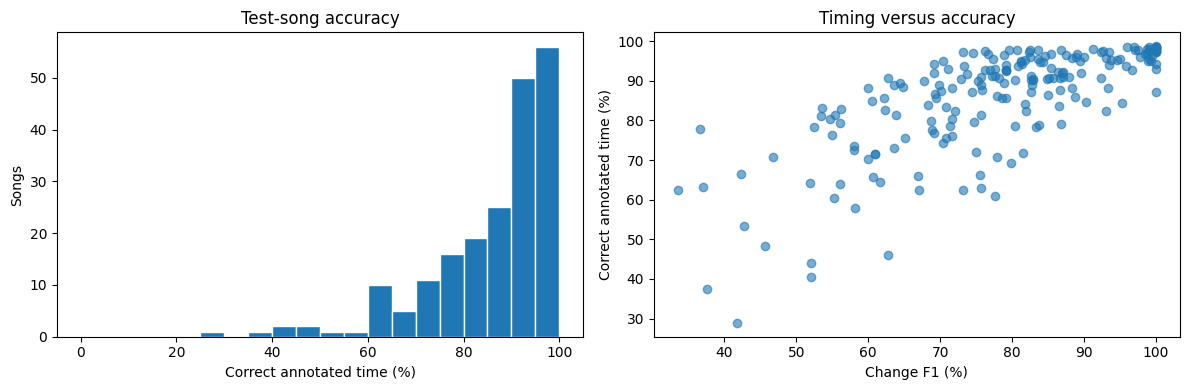

In [15]:
display(metrics[metric_columns].sort_values("all_label_accuracy").head(10).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(100*metrics.all_label_accuracy, bins=np.arange(0, 105, 5), edgecolor="white")
axes[0].set(xlabel="Correct annotated time (%)", ylabel="Songs", title="Test-song accuracy")
axes[1].scatter(100*metrics.onset_f1, 100*metrics.all_label_accuracy, alpha=.6)
axes[1].set(xlabel="Change F1 (%)", ylabel="Correct annotated time (%)", title="Timing versus accuracy")
plt.tight_layout()
plt.show()


## 12. Export locations for a separate playback notebook
The training notebook ends with files, not an audio player or waveform/playhead preview.

Each test-song CSV contains predicted chord intervals in seconds. `bar` and `quarter` are blank because there is no beat tracker here. `next_chord` and `next_time_s` remain available for your separate playback notebook.

The small `playback_manifest.json` links the winning model, prediction folder, test-song IDs and original audio files. It records paths; it does not copy audio or render a video. The saved model can also predict new audio using step 14.


In [16]:
validation_path = evaluation_path / "validation_comparison.csv"
validation_results[result_columns].to_csv(validation_path, index=False)
manifest = {
    "model_path": str(model_path),
    "prediction_folder": str(evaluation_path),
    "prediction_filename": "{song_id}_predictions.csv",
    "audio_folder": str(audio_folder),
    "audio_files": {song_id: str(audio_files[song_id]) for song_id in split["test"] if song_id in audio_files},
    "test_song_ids": split["test"],
    "config": chosen_config,
    "weight": chosen_weight,
    "sample_rate": sample_rate,
    "beat_positions_available": False
}
manifest_path = evaluation_path / "playback_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))
for name, path in {
    "Winning model": model_path,
    "Test predictions": evaluation_path,
    "Audio boundary report": evaluation_path / "test_audio_boundaries.csv",
    "Per-song metrics": evaluation_path / "test_song_metrics.csv",
    "Test summary": evaluation_path / "test_play_along_summary.csv",
    "Validation comparison": validation_path,
    "Playback manifest": manifest_path
}.items():
    print(f"{name}: {path}")
print(f"Example prediction: {evaluation_path / (split['test'][0] + '_predictions.csv')}")


Winning model: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/window_hmm_4f12560a1fd5a9f6.npz
Test predictions: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/evaluation/4f12560a1fd5a9f6
Audio boundary report: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/evaluation/4f12560a1fd5a9f6/test_audio_boundaries.csv
Per-song metrics: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/evaluation/4f12560a1fd5a9f6/test_song_metrics.csv
Test summary: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/evaluation/4f12560a1fd5a9f6/test_play_along_summary.csv
Validation comparison: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_window_hmm_results/evaluation/4f12560a1fd5a9f6/validation_comparison.c

## 13. Optional: inspect one song's errors
Compare ground truth and saved predictions for a short excerpt, then list the chord confusions responsible for the most wrong seconds. This is inspection only; it does not change the chosen model.


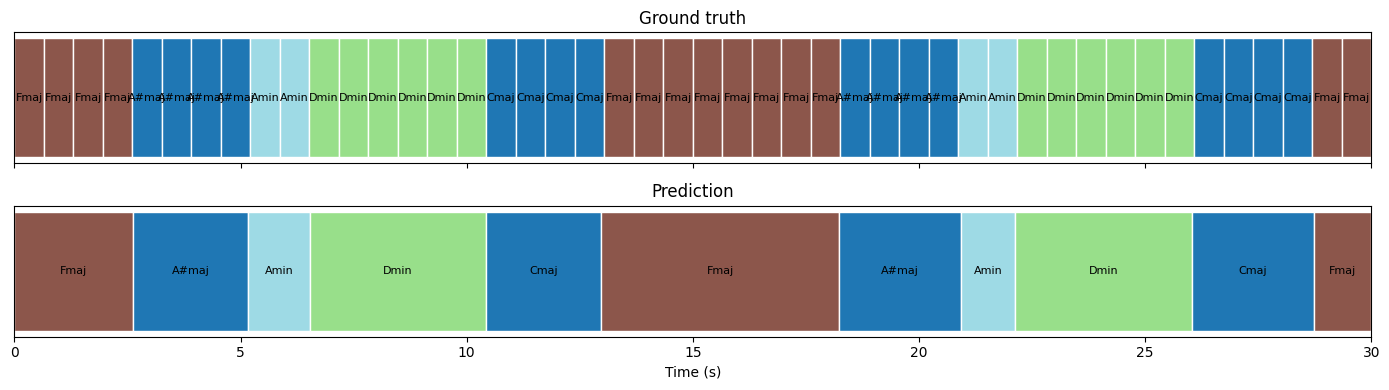

,true,predicted,seconds
24,Gmin,Gmaj,2.607256
18,Fmaj,Fmin,1.874138
7,Cmaj,Fmaj,0.148586
13,Dmin,Cmaj,0.131308
4,Amin,A#maj,0.126550
3,A#maj,Fmaj,0.101072
5,Amin,Dmin,0.090557
9,D#maj,Dmin,0.084649
0,A#maj,Amin,0.082641
19,Fmaj,Gmin,0.082359


In [17]:
song_id = split["test"][0]
start_time, end_time = 0.0, 30.0
prediction = load_interval_csv(evaluation_path / f"{song_id}_predictions.csv")
truth = ground_truth[song_id]
fig, axes = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
for ax, table, title in zip(axes, [truth, prediction], ["Ground truth", "Prediction"]):
    for row in table.itertuples():
        left, right = max(row.start, start_time), min(row.end, end_time)
        if right > left:
            color = "lightgray" if row.chord == "N" else plt.cm.tab20(state_to_id[row.chord] % 20)
            ax.barh(0, right-left, left=left, color=color, edgecolor="white")
            if right-left > .3:
                ax.text((left+right)/2, 0, row.chord, ha="center", va="center", fontsize=8)
    ax.set(yticks=[], title=title, xlim=(start_time, end_time))
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()
duration = float(metrics.set_index("song_id").loc[song_id, "duration_s"])
# Exact-time confusion for this song (rows=true, columns=predicted).
boundaries = np.unique(np.clip(np.r_[0, duration, truth.start, truth.end, prediction.start, prediction.end], 0, duration))
true_labels = labels_at((boundaries[:-1]+boundaries[1:])/2, truth)
predicted_labels = labels_at((boundaries[:-1]+boundaries[1:])/2, prediction)
errors = pd.DataFrame({"true": true_labels, "predicted": predicted_labels, "seconds": np.diff(boundaries)})
errors = errors[errors.true.isin(states) & errors.true.ne(errors.predicted)]
display(errors.groupby(["true", "predicted"], as_index=False).seconds.sum().nlargest(10, "seconds"))


## 14. Optional: predict a new recording
After a restart, run setup and the helper definitions, then set `model_path` to the saved model. New audio uses the saved sample rate, filter, feature method and smoothing weight. No ground-truth file is needed.

In [18]:
new_audio_path = Path("/content/drive/MyDrive/my_song.wav")
if new_audio_path.exists():
    with np.load(model_path, allow_pickle=False) as saved:
        saved_selection = json.loads(str(saved["selection"]))
        prediction_model = {key: saved[key] for key in ["means", "covariances", "transitions", "initial"]}
    assert saved_selection["states"] == states.tolist()
    sample_rate = saved_selection["experiment"]["sr"]
    low_cut_hz, high_cut_hz, filter_order = saved_selection["experiment"]["filter"]
    audio, _ = librosa.load(new_audio_path, sr=sample_rate, mono=True)
    audio = filter_audio(audio, sample_rate)
    features, centers, edges = extract_features(audio, saved_selection["config"])
    ids = decode(emission_scores(features, prediction_model), prediction_model, saved_selection["weight"])
    prediction = merge_intervals(interval_table(edges, ids))
    assert valid_prediction_bounds(prediction, len(audio) / sample_rate)
    output = play_along_csv(prediction)
    output_path = results_path / f"{new_audio_path.stem}_window_chords.csv"
    output.to_csv(output_path, index=False)
    display(output.head(20))
    print("Saved:", output_path)
else:
    print("Optional: set new_audio_path to your recording.")


Optional: set new_audio_path to your recording.


## 15. Optional: Insept a test song's predicted timed chords

In [20]:
song_id = split["test"][0]
prediction_path = evaluation_path / f"{song_id}_predictions.csv"

df = pd.read_csv(prediction_path)[["time_s", "end_time_s", "chord"]]
df = df.rename(columns={"time_s": "start_time_s"})

truth = merge_intervals(ground_truth[song_id])

df[["true_start_time_s", "true_end_time_s", "true_chord"]] = pd.NA

for i, row in df.iterrows():
    overlap = (
        np.minimum(truth.end, row.end_time_s)
        - np.maximum(truth.start, row.start_time_s)
    ).clip(lower=0)

    if overlap.max() > 0:
        match = truth.loc[overlap.idxmax()]
        df.loc[i, ["true_start_time_s", "true_end_time_s", "true_chord"]] = [
            match.start, match.end, match.chord
        ]

print(f"Test song: {song_id}")
display(df)

Test song: 0001


,start_time_s,end_time_s,chord,true_start_time_s,true_end_time_s,true_chord
0,0.000000,2.625397,Fmaj,0.0,2.608696,Fmaj
1,2.625397,5.175782,A#maj,2.608696,5.217391,A#maj
2,5.175782,6.525986,Amin,5.217391,6.521739,Amin
3,6.525986,10.426576,Dmin,6.521739,10.434783,Dmin
4,10.426576,12.976961,Cmaj,10.434783,13.043479,Cmaj
5,12.976961,18.227755,Fmaj,13.043479,18.26087,Fmaj
6,18.227755,20.928163,A#maj,18.26087,20.869566,A#maj
7,20.928163,22.128345,Amin,20.869566,22.173914,Amin
8,22.128345,26.028934,Dmin,22.173914,26.086956,Dmin
9,26.028934,28.729342,Cmaj,26.086956,28.695652,Cmaj
